# 03 — Clustering: UCI HAR

**Goal:** compare the HW1 K-means and fuzzy C-means implementations with activity labels on subject-disjoint train/test windows.

- Rebuild inputs using the §9 pipeline in `02_preprocessing_pca.ipynb`; no saved arrays. Save 02 after changing its literal `N_COMPONENTS` or `STANDARDIZE`, then rerun this notebook.
- Fit preprocessing and clustering on **train only**. Test windows use the training centres. Labels are used only for evaluation; restarts are selected by the training clustering objective.
- Headline **matched accuracy** uses a Hungarian cluster-to-label mapping learned on train and frozen for test. **Split-optimal accuracy** separately fits a permutation on each evaluated split; it is a descriptive upper bound, not fixed-map predictive accuracy.
- FCM hard labels use maximum membership, with fuzzifier $m=2$. PC1–PC2 plots are projections, not the full clustering space.
- Figures are saved as PDF + PNG through `plot_style` to `figures/clustering/`. ✍️ cells are for my own interpretation.

In [1]:
import sys
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display
from threadpoolctl import threadpool_limits

sys.path.append("../src")
from har_data import load_har
from preprocess import notebook_settings, make_prep, Standardizer
from clustering import (best_kmeanx, best_fcm, predict_kmeans, predict_fcm,
                        clustering_metrics, contingency_table, hungarian_mapping,
                        matched_accuracy, partition_coefficient, mean_max_membership,
                        squared_distances)
import plot_style as ps

ps.apply_style()
save = ps.saver("../figures/clustering")
d = load_har()
ACT = d.activities
LABELS = sorted(ACT)
NAMES = [ps.SHORT[ACT[i]] for i in LABELS]
SEED, N_INIT, MAX_ITER, TOL, M = 42, 10, 1000, 1e-5, 2
print(f"seed={SEED}, restarts={N_INIT}, max_iter={MAX_ITER}, tolerance={TOL}, m={M}")

seed=42, restarts=10, max_iter=1000, tolerance=1e-05, m=2


## 1. Rebuild the training pipeline

Both notebooks call `make_prep` in `src/preprocess.py`. The settings reader extracts only literal assignments from saved 02; it does not execute its cells. Preprocessing is timed separately. Clustering fit/predict timings use one BLAS thread and exclude preprocessing, metrics and figures.

In [2]:
settings = notebook_settings()
print("Saved decisions from 02:", settings)
prep = make_prep(settings["N_COMPONENTS"], settings["STANDARDIZE"])
start = perf_counter()
with threadpool_limits(limits=1):
    T_train = prep.fit_transform(d.X_train)
    T_test = prep.transform(d.X_test)
print(f"preprocessing fit + transform: {perf_counter() - start:.3f} s")

# The comparison always uses z-scores on the same train-selected columns.
X_train_dd = prep[0].transform(d.X_train)
X_test_dd = prep[0].transform(d.X_test)
z_scaler = Standardizer().fit(X_train_dd)
Z_train = z_scaler.transform(X_train_dd)
Z_test = z_scaler.transform(X_test_dd)
y_train, y_test = d.y_train.to_numpy(), d.y_test.to_numpy()
print(f"PCA: train {T_train.shape}, test {T_test.shape}; no PCA: {Z_train.shape[1]} features")
print("PCA retained training variance:", prep[-1].explained_variance_ratio_.sum())
assert not set(d.subject_train) & set(d.subject_test)
assert len(T_train) == len(y_train) and len(T_test) == len(y_test)
# For a future one-component choice, use a constant vertical coordinate.
def view2(T):
    return T[:, :2] if T.shape[1] >= 2 else np.column_stack([T[:, 0], np.zeros(len(T))])
V_train, V_test = view2(T_train), view2(T_test)

Saved decisions from 02: {'STANDARDIZE': True, 'N_COMPONENTS': 0.95}


preprocessing fit + transform: 1.335 s
PCA: train (7352, 103), test (2947, 103); no PCA: 540 features
PCA retained training variance: 0.950724601263107


## 2. Shared experiment and figure helpers

K-means minimizes SSE; FCM minimizes $\sum_{ij}u_{ij}^m\|x_i-c_j\|^2$. The port retains HW1 random initialization, weighted means and distance-ratio memberships. The selected restart's iteration count, objective, centre spacing and hard cluster sizes are recorded to expose non-convergence or nearly coincident FCM centres. Partition coefficient is $\frac1n\sum_{ij}u_{ij}^2$ (uniform membership: $1/k$).

In [3]:
runs, metric_rows, diagnostic_rows, membership_rows = {}, [], [], []

def run_pair(space, Xtr, Xte, k, ytr, yte, labels, names):
    for method, fit in (("K-means", best_kmeanx), ("FCM", best_fcm)):
        key = f"{space} / k={k} / {method}"
        with threadpool_limits(limits=1):
            start = perf_counter()
            result = fit(Xtr, k, n_init=N_INIT, max_iter=MAX_ITER, tol=TOL, seed=SEED,
                         **({"m": M} if method == "FCM" else {}))
            fit_seconds = perf_counter() - start
            start = perf_counter()
            Utest = predict_fcm(Xte, result.centres, M) if method == "FCM" else None
            test_labels = Utest.argmax(axis=1) if Utest is not None else predict_kmeans(Xte, result.centres)
            predict_seconds = perf_counter() - start
        mapping = hungarian_mapping(ytr, result.labels)
        runs[key] = dict(result=result, train=result.labels, test=test_labels,
                         Utrain=result.memberships, Utest=Utest, ytrain=ytr, ytest=yte,
                         labels=labels, names=names, k=k, mapping=mapping)
        distances = squared_distances(result.centres, result.centres)
        np.fill_diagonal(distances, np.inf)
        diagnostic_rows.append({"run": key, "iterations": result.n_iter,
                                "converged": result.converged, "objective": result.objective,
                                "min centre distance": np.sqrt(distances.min()),
                                "train cluster sizes": np.bincount(result.labels, minlength=k).tolist(),
                                "fit seconds (all restarts)": fit_seconds,
                                "test predict seconds": predict_seconds})
        for split, truth, pred, U in (("train", ytr, result.labels, result.memberships),
                                      ("test", yte, test_labels, Utest)):
            row = {"space": space, "k": k, "method": method, "split": split,
                   **clustering_metrics(truth, pred, mapping),
                   "split-optimal accuracy": matched_accuracy(truth, pred),
                   "partition coefficient": partition_coefficient(U) if U is not None else np.nan,
                   "fit seconds": fit_seconds, "test predict seconds": predict_seconds}
            metric_rows.append(row)
            if U is not None:
                assert np.allclose(U.sum(axis=1), 1) and np.isfinite(U).all()
                means = mean_max_membership(truth, U)
                for label, name in zip(labels, names):
                    membership_rows.append({"run": key, "split": split, "class": name,
                                            "mean max membership": means.loc[label]})
        print(key, "converged:", result.converged, "iterations:", result.n_iter)
        assert result.converged, f"Iteration cap reached: {key}"

def metrics(k=None):
    frame = pd.DataFrame(metric_rows)
    if k is not None:
        frame = frame.loc[frame["k"] == k]
    return frame.set_index(["space", "k", "method", "split"])

def scatter_run(key, filename):
    run = runs[key]
    palette = plt.get_cmap("tab10").colors
    fig, axes = plt.subplots(2, 2, figsize=(ps.PAGE_W, 5.8), sharex=True, sharey=True)
    for row, (split, V, truth) in enumerate((("train", V_train, run["ytrain"]),
                                           ("test", V_test, run["ytest"]))):
        for col, values in enumerate((run[split], truth)):
            ax = axes[row, col]
            ids = range(run["k"]) if col == 0 else run["labels"]
            names = [f"C{i}" for i in ids] if col == 0 else run["names"]
            for j, (label, name) in enumerate(zip(ids, names)):
                mask = values == label
                ax.scatter(V[mask, 0], V[mask, 1], s=2, alpha=.45, color=palette[j],
                           linewidths=0, rasterized=True)
            ax.set_title(f"{split.title()}: {'clusters' if col == 0 else 'true activity'}")
            if row == 0:
                ax.legend([Patch(color=palette[j]) for j in range(len(names))], names,
                          ncol=3, fontsize=6, loc="lower center", bbox_to_anchor=(.5, 1.13))
            ax.set_xlabel("PC1 score")
            ax.set_ylabel("PC2 score" if T_train.shape[1] >= 2 else "No second component")
    fig.suptitle(key, y=1.01)
    fig.tight_layout()
    save(fig, filename); plt.show()

def heatmap_run(key, filename):
    run = runs[key]
    tables = [contingency_table(run[f"y{split}"], run[split], run["labels"], range(run["k"]))
              for split in ("train", "test")]
    fig, axes = plt.subplots(1, 2, figsize=(ps.PAGE_W, 3.1), constrained_layout=True)
    vmax = max(table.to_numpy().max() for table in tables)
    for ax, split, table in zip(axes, ("Train", "Test"), tables):
        values = table.to_numpy()
        im = ax.imshow(values, aspect="auto", cmap=ps.SEQUENTIAL, vmin=0, vmax=vmax)
        ax.set_yticks(range(len(run["labels"])), run["names"])
        ax.set_xticks(range(run["k"]), [f"C{i}" for i in range(run["k"])])
        ax.set_xlabel("Cluster"); ax.set_title(split); ax.grid(False)
        for (i, j), value in np.ndenumerate(values):
            ax.text(j, i, str(value), ha="center", va="center", fontsize=6,
                    color="white" if value > .55 * vmax else ps.INK)
    fig.colorbar(im, ax=axes, label="Windows", shrink=.8)
    fig.suptitle(key)
    save(fig, filename); plt.show()

def membership_run(key, filename):
    run = runs[key]
    fig, axes = plt.subplots(1, 2, figsize=(ps.PAGE_W, 2.9), sharey=True)
    for ax, split in zip(axes, ("train", "test")):
        U, truth = run[f"U{split}"], run[f"y{split}"]
        values = [U.max(axis=1)[truth == label] for label in run["labels"]]
        bp = ax.boxplot(values, widths=.6, patch_artist=True, showfliers=False,
                        medianprops=dict(color=ps.INK))
        for box in bp["boxes"]:
            box.set(facecolor=ps.BLUE, alpha=.65)
        ax.axhline(1 / run["k"], color=ps.INK2, ls="--", lw=.8)
        ax.set_xticks(range(1, len(run["names"]) + 1), run["names"], rotation=35, ha="right")
        ax.set_title(split.title()); ax.set_ylim(0, 1.02); ax.grid(axis="x", visible=False)
        ax.set_ylabel("Maximum FCM membership")
    fig.suptitle(key + " (dashed: uniform membership)", fontsize=9)
    fig.tight_layout()
    save(fig, filename); plt.show()

## 3. Six clusters on PCA scores

In [4]:
run_pair("PCA", T_train, T_test, 6, y_train, y_test, LABELS, NAMES)
display(metrics(6).round(4))
display(pd.DataFrame(diagnostic_rows).set_index("run"))

PCA / k=6 / K-means converged: True iterations: 10


PCA / k=6 / FCM converged: True iterations: 71


ARI     NMI  matched accuracy  \
space k method  split                                     
PCA   6 K-means train  0.4227  0.5607            0.5411   
                test   0.4428  0.5910            0.5405   
        FCM     train  0.2916  0.4605            0.4378   
                test   0.3200  0.4828            0.4829   

                       split-optimal accuracy  partition coefficient  \
space k method  split                                                  
PCA   6 K-means train                  0.5411                    NaN   
                test                   0.5738                    NaN   
        FCM     train                  0.4378                 0.2383   
                test                   0.4829                 0.2370   

                       fit seconds  test predict seconds  
space k method  split                                     
PCA   6 K-means train       0.6950                0.0007  
                test        0.6950                0.0007  
        FCM     train       1.1274                0.0008  
                test        1.1274                0.0008

,iterations,converged,objective,min centre distance,train cluster sizes,fit seconds (all restarts),test predict seconds
run,,,,,,,
PCA / k=6 / K-means,10,True,1.591184e+06,9.168408e+00,"[239, 1921, 1726, 1321, 1197, 948]",0.695013,0.000674
PCA / k=6 / FCM,71,True,5.313968e+05,1.455247e-08,"[1730, 1507, 0, 2337, 1778, 0]",1.127377,0.000783


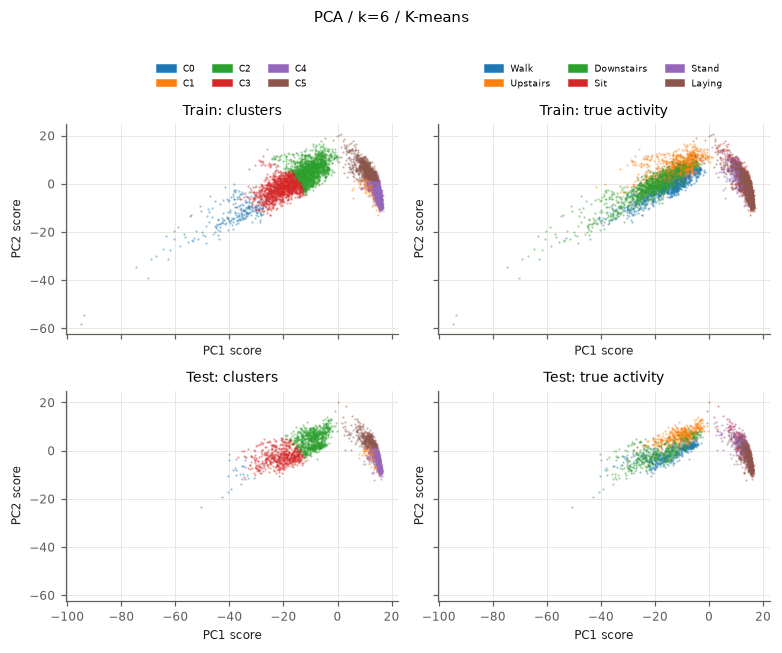

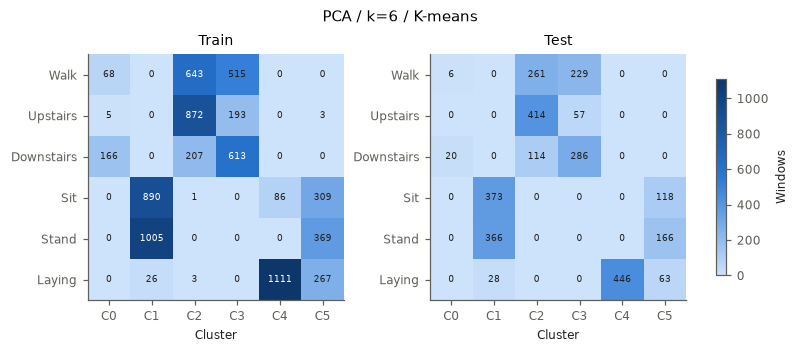

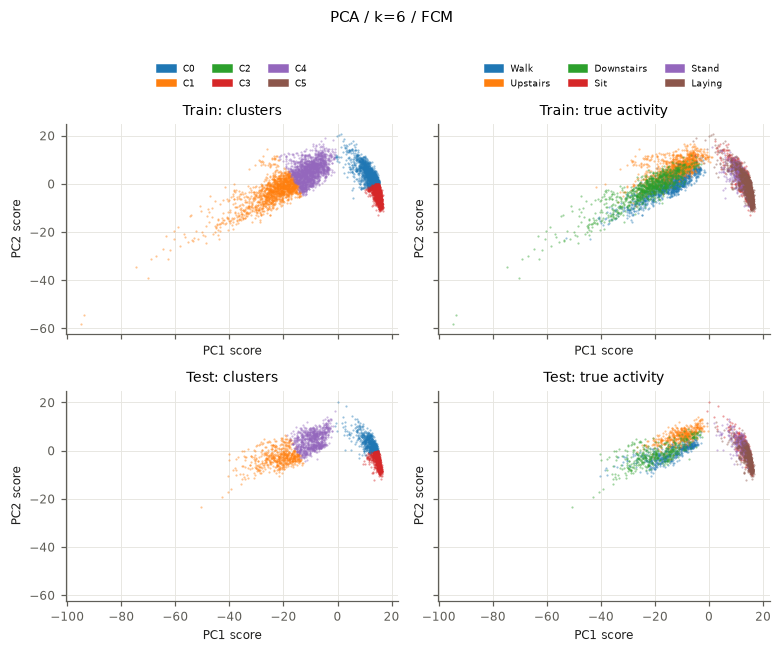

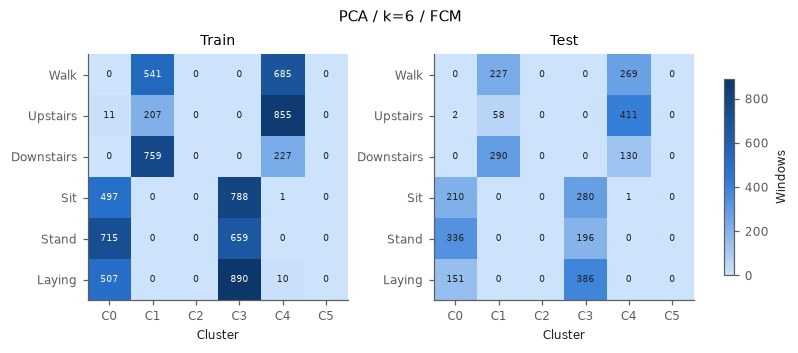

In [5]:
for method, stem in (("K-means", "kmeans"), ("FCM", "fcm")):
    key = f"PCA / k=6 / {method}"
    scatter_run(key, f"pca_{stem}_scatter")
    heatmap_run(key, f"pca_{stem}_contingency")

✍️ **Observations — activity merges:** *(Which activities merge in the contingency tables? Why might their motion or posture features overlap? Does PC1–PC2 reveal the same structure as the full clustering space?)*

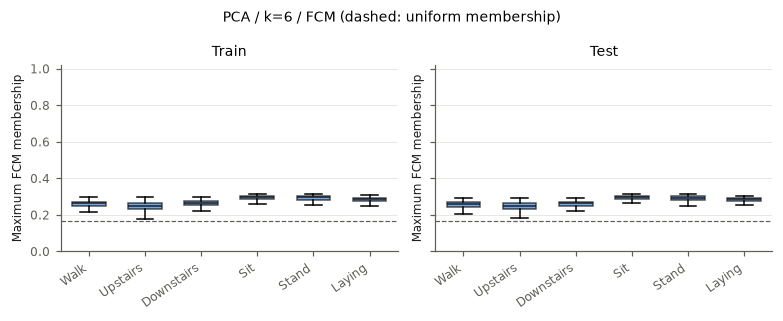

run        PCA / k=6 / FCM        
split                train    test
class                             
Downstairs          0.2614  0.2597
Laying              0.2788  0.2817
Sit                 0.2899  0.2920
Stand               0.2902  0.2881
Upstairs            0.2468  0.2454
Walk                0.2581  0.2569

In [6]:
membership_run("PCA / k=6 / FCM", "pca_fcm_memberships")
display(pd.DataFrame(membership_rows).pivot(index="class", columns=["run", "split"],
                                           values="mean max membership").round(4))

✍️ **Interpretation — K-means vs FCM:** *(Which method aligns better with activities? What do the partition coefficient, per-class maximum memberships, centre spacing and hard cluster sizes reveal? Are maximum-membership hard labels informative when memberships are nearly tied?)*

## 4. Two clusters: moving vs still

Moving = walking, upstairs, downstairs (activity IDs 1–3); still = sitting, standing, laying (4–6). Both algorithms are fit again on the same PCA train scores with $k=2$. The binary labels are evaluation targets only.

PCA / k=2 / K-means converged: True iterations: 6


PCA / k=2 / FCM converged: True iterations: 17


ARI     NMI  matched accuracy  \
space k method  split                                     
PCA   2 K-means train  0.9891  0.9727            0.9973   
                test   0.9973  0.9925            0.9993   
        FCM     train  0.9881  0.9704            0.9970   
                test   0.9959  0.9885            0.9990   

                       split-optimal accuracy  partition coefficient  \
space k method  split                                                  
PCA   2 K-means train                  0.9973                    NaN   
                test                   0.9993                    NaN   
        FCM     train                  0.9970                 0.7148   
                test                   0.9990                 0.7111   

                       fit seconds  test predict seconds  
space k method  split                                     
PCA   2 K-means train       0.1122                0.0005  
                test        0.1122                0.0005  
        FCM     train       0.2274                0.0003  
                test        0.2274                0.0003

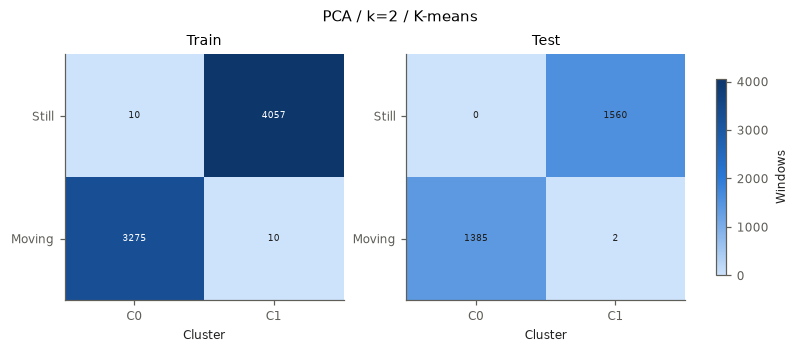

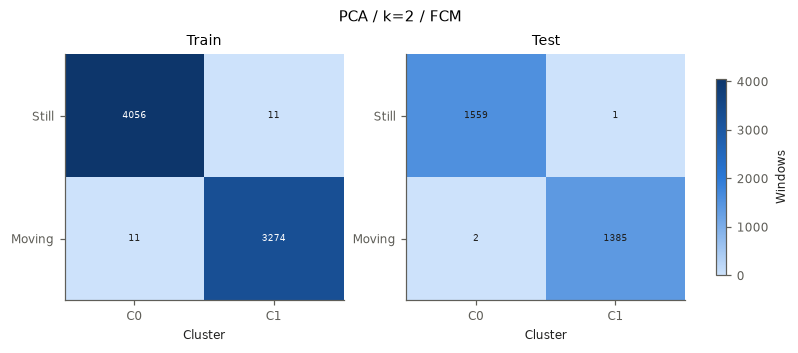

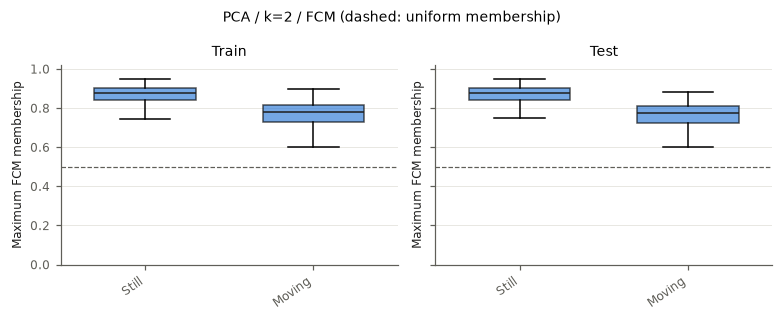

split,test,train
class,,
Moving,0.7615,0.7661
Still,0.8614,0.8585


In [7]:
moving_train = (y_train <= 3).astype(int)
moving_test = (y_test <= 3).astype(int)
run_pair("PCA", T_train, T_test, 2, moving_train, moving_test, [0, 1], ["Still", "Moving"])
display(metrics(2).round(4))
for method, stem in (("K-means", "kmeans"), ("FCM", "fcm")):
    heatmap_run(f"PCA / k=2 / {method}", f"moving_still_{stem}_contingency")
membership_run("PCA / k=2 / FCM", "moving_still_fcm_memberships")
display(pd.DataFrame(membership_rows).query("run == 'PCA / k=2 / FCM'")
        .pivot(index="class", columns="split", values="mean max membership").round(4))

✍️ **Interpretation — moving vs still:** *(Does k = 2 recover movement intensity better than k = 6 recovers individual activities? What does this say about the dominant geometry and about choosing k from the number of activity labels?)*

## 5. Comparison: z-scored features without PCA

Use the same 540 train-selected columns, z-scored with training statistics, with the same seeds, restarts, convergence criteria and $k=6$. Each fit time includes all ten restarts; the same fit time is repeated for its train/test rows. Test prediction time excludes scoring. Timing is descriptive for this machine, not a repeated benchmark.

No PCA / k=6 / K-means converged: True iterations: 11


No PCA / k=6 / FCM converged: True iterations: 47


ARI     NMI  matched accuracy  \
space  k method  split                                     
PCA    6 K-means train  0.4227  0.5607            0.5411   
                 test   0.4428  0.5910            0.5405   
         FCM     train  0.2916  0.4605            0.4378   
                 test   0.3200  0.4828            0.4829   
No PCA 6 K-means train  0.4229  0.5610            0.5423   
                 test   0.4417  0.5902            0.5548   
         FCM     train  0.2912  0.4602            0.4369   
                 test   0.3178  0.4810            0.4801   

                        split-optimal accuracy  partition coefficient  \
space  k method  split                                                  
PCA    6 K-means train                  0.5411                    NaN   
                 test                   0.5738                    NaN   
         FCM     train                  0.4378                 0.2383   
                 test                   0.4829                 0.2370   
No PCA 6 K-means train                  0.5423                    NaN   
                 test                   0.5728                    NaN   
         FCM     train                  0.4369                 0.2329   
                 test                   0.4801                 0.2308   

                        fit seconds  test predict seconds  
space  k method  split                                     
PCA    6 K-means train       0.6950                0.0007  
                 test        0.6950                0.0007  
         FCM     train       1.1274                0.0008  
                 test        1.1274                0.0008  
No PCA 6 K-means train       4.5189                0.0011  
                 test        4.5189                0.0011  
         FCM     train       3.0327                0.0013  
                 test        3.0327                0.0013

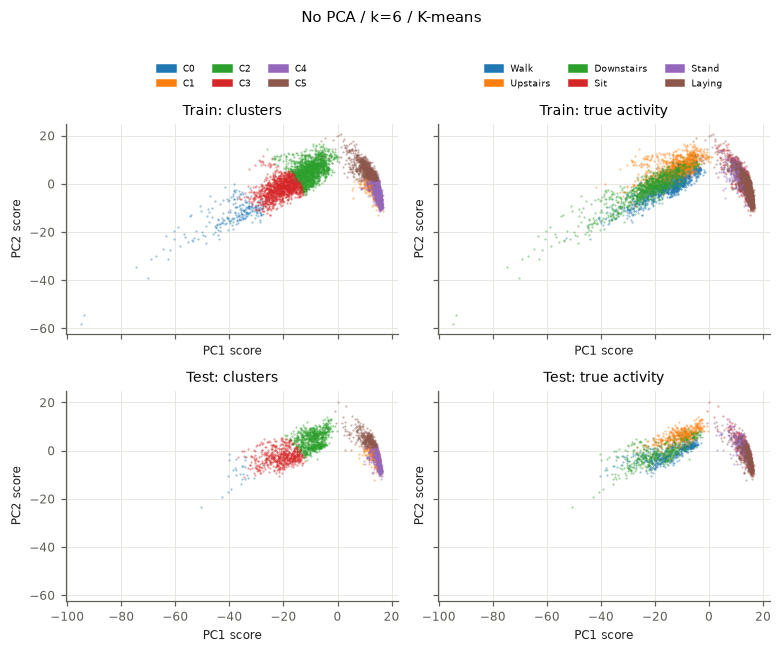

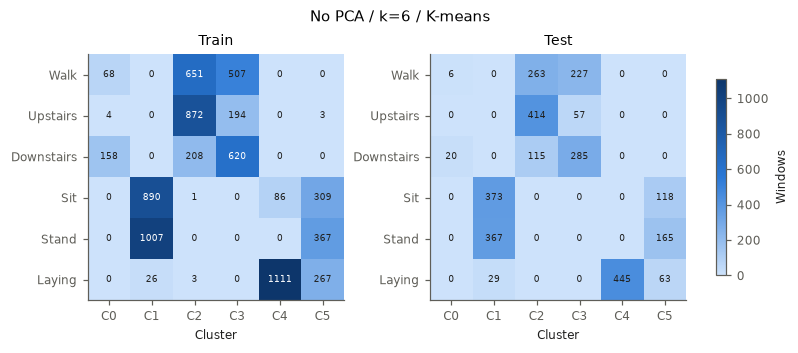

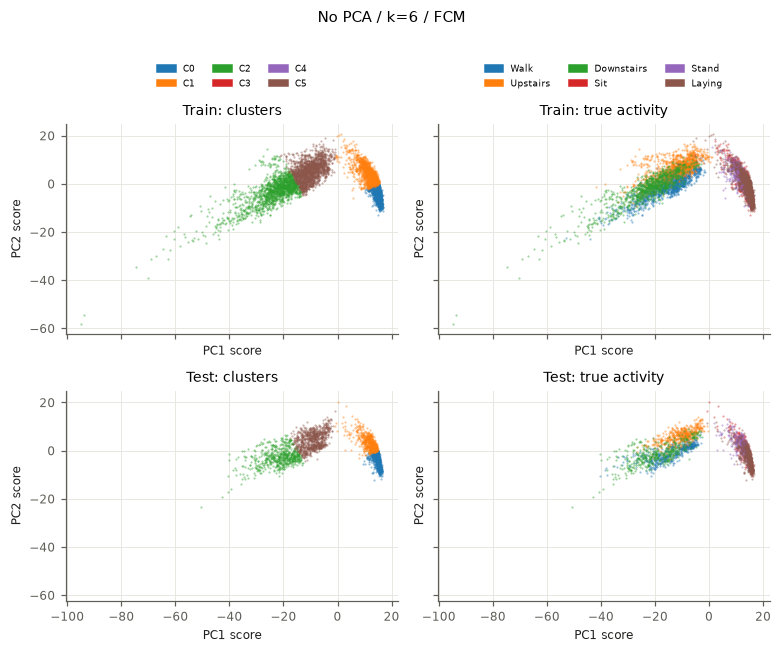

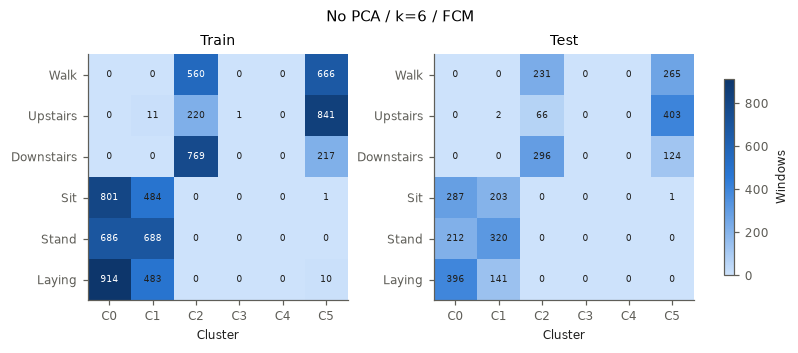

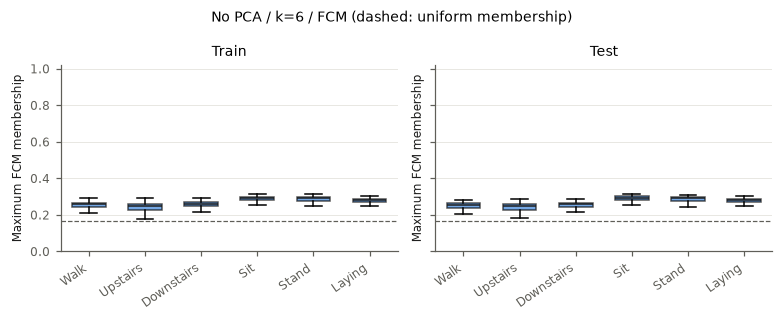

split,test,train
class,,
Downstairs,0.2536,0.2561
Laying,0.2767,0.2748
Sit,0.2877,0.2857
Stand,0.2835,0.2860
Upstairs,0.2409,0.2431
Walk,0.2513,0.2538


In [8]:
run_pair("No PCA", Z_train, Z_test, 6, y_train, y_test, LABELS, NAMES)
display(metrics(6).round(4))
for method, stem in (("K-means", "kmeans"), ("FCM", "fcm")):
    key = f"No PCA / k=6 / {method}"
    # Projection uses the training PCA axes solely for visual comparison.
    scatter_run(key, f"no_pca_{stem}_scatter")
    heatmap_run(key, f"no_pca_{stem}_contingency")
membership_run("No PCA / k=6 / FCM", "no_pca_fcm_memberships")
display(pd.DataFrame(membership_rows).query("run == 'No PCA / k=6 / FCM'")
        .pivot(index="class", columns="split", values="mean max membership").round(4))

✍️ **Interpretation — PCA vs no PCA:** *(How do ARI, NMI, matched accuracy, FCM memberships and runtime change? Is the retained variance a useful proxy for preserving activity separation? Which tradeoff would justify changing the placeholder k in 02?)*

## 6. Train/test and convergence audit

In [9]:
display(metrics().round(4))
display(pd.DataFrame(diagnostic_rows).set_index("run"))
display(pd.DataFrame(membership_rows).pivot(index=["run", "class"], columns="split",
                                           values="mean max membership").round(4))
print("Preprocessing and all cluster centres were fitted on train only.")
print("Matched accuracy uses the training Hungarian map; split-optimal accuracy is reported separately.")
print("Every selected restart converged; all FCM membership rows sum to one.")

ARI     NMI  matched accuracy  \
space  k method  split                                     
PCA    6 K-means train  0.4227  0.5607            0.5411   
                 test   0.4428  0.5910            0.5405   
         FCM     train  0.2916  0.4605            0.4378   
                 test   0.3200  0.4828            0.4829   
       2 K-means train  0.9891  0.9727            0.9973   
                 test   0.9973  0.9925            0.9993   
         FCM     train  0.9881  0.9704            0.9970   
                 test   0.9959  0.9885            0.9990   
No PCA 6 K-means train  0.4229  0.5610            0.5423   
                 test   0.4417  0.5902            0.5548   
         FCM     train  0.2912  0.4602            0.4369   
                 test   0.3178  0.4810            0.4801   

                        split-optimal accuracy  partition coefficient  \
space  k method  split                                                  
PCA    6 K-means train                  0.5411                    NaN   
                 test                   0.5738                    NaN   
         FCM     train                  0.4378                 0.2383   
                 test                   0.4829                 0.2370   
       2 K-means train                  0.9973                    NaN   
                 test                   0.9993                    NaN   
         FCM     train                  0.9970                 0.7148   
                 test                   0.9990                 0.7111   
No PCA 6 K-means train                  0.5423                    NaN   
                 test                   0.5728                    NaN   
         FCM     train                  0.4369                 0.2329   
                 test                   0.4801                 0.2308   

                        fit seconds  test predict seconds  
space  k method  split                                     
PCA    6 K-means train       0.6950                0.0007  
                 test        0.6950                0.0007  
         FCM     train       1.1274                0.0008  
                 test        1.1274                0.0008  
       2 K-means train       0.1122                0.0005  
                 test        0.1122                0.0005  
         FCM     train       0.2274                0.0003  
                 test        0.2274                0.0003  
No PCA 6 K-means train       4.5189                0.0011  
                 test        4.5189                0.0011  
         FCM     train       3.0327                0.0013  
                 test        3.0327                0.0013

,iterations,converged,objective,min centre distance,train cluster sizes,fit seconds (all restarts),test predict seconds
run,,,,,,,
PCA / k=6 / K-means,10,True,1.591184e+06,9.168408e+00,"[239, 1921, 1726, 1321, 1197, 948]",0.695013,0.000674
PCA / k=6 / FCM,71,True,5.313968e+05,1.455247e-08,"[1730, 1507, 0, 2337, 1778, 0]",1.127377,0.000783
PCA / k=2 / K-means,6,True,2.091786e+06,3.042966e+01,"[3285, 4067]",0.112151,0.000477
PCA / k=2 / FCM,17,True,1.594190e+06,2.780266e+01,"[4067, 3285]",0.227423,0.000350
No PCA / k=6 / K-means,11,True,1.786379e+06,9.173764e+00,"[230, 1923, 1735, 1321, 1197, 946]",4.518889,0.001080
No PCA / k=6 / FCM,47,True,5.749925e+05,2.380660e-07,"[2401, 1666, 1549, 1, 0, 1735]",3.032667,0.001325


split                            test   train
run                class                     
No PCA / k=6 / FCM Downstairs  0.2536  0.2561
                   Laying      0.2767  0.2748
                   Sit         0.2877  0.2857
                   Stand       0.2835  0.2860
                   Upstairs    0.2409  0.2431
                   Walk        0.2513  0.2538
PCA / k=2 / FCM    Moving      0.7615  0.7661
                   Still       0.8614  0.8585
PCA / k=6 / FCM    Downstairs  0.2597  0.2614
                   Laying      0.2817  0.2788
                   Sit         0.2920  0.2899
                   Stand       0.2881  0.2902
                   Upstairs    0.2454  0.2468
                   Walk        0.2569  0.2581

Preprocessing and all cluster centres were fitted on train only.
Matched accuracy uses the training Hungarian map; split-optimal accuracy is reported separately.
Every selected restart converged; all FCM membership rows sum to one.


✍️ **Interpretation — train vs test:** *(How well does clustering transfer to unseen subjects? Which activity rows change most? Does the train-fitted Hungarian mapping transfer, and how much does test-optimal rematching change accuracy?)*

## 7. Summary of unsupervised results ✍️

*(3–6 bullets in my own words that will become the paper's unsupervised-results paragraph. Cover: six-class alignment and merged activities; K-means vs FCM and membership ambiguity; PCA vs no PCA and runtime; moving vs still; subject-disjoint train/test transfer; limitations of clustering scores and the current placeholder PCA dimension.)*

-
-
-

**Figures saved** (`figures/clustering/`): `pca_{kmeans,fcm}_scatter`, `pca_{kmeans,fcm}_contingency`, `pca_fcm_memberships`, `moving_still_{kmeans,fcm}_contingency`, `moving_still_fcm_memberships`, `no_pca_{kmeans,fcm}_scatter`, `no_pca_{kmeans,fcm}_contingency`, `no_pca_fcm_memberships` (each as .pdf and .png).